In [29]:
import pandas as pd
import json
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("Biblioteker lastet inn!")

Biblioteker lastet inn!


In [49]:
# Last inn klassifiserte data
with open("../data/klassifisert.json", "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)
print(f"Lastet {len(df)} klassifiserte diagnoser")
df.head()

Lastet 3103 klassifiserte diagnoser


,id,diagnosis,diagnosis_clean,kategori
0,ID_0001,hysteria ?,hysteria ?,1. Hysteria
1,ID_0002,hysteria 7,hysteria 7,1. Hysteria
2,ID_0003,hysteria,hysteria,1. Hysteria
3,ID_0004,202|hysteria,202|hysteria,1. Hysteria
4,ID_0005,hysteria,hysteria,1. Hysteria


In [ ]:


# Opprinnelig: tilfeldig utvalg på 100 poster
# Byttet til stratifisert utvalg (se neste celle) fordi 
# tilfeldig utvalg ikke garanterer representasjon av sjeldne kategorier
# df_sample = df.sample(n=min(100, len(df)), random_state=42).copy()

# Ta 20 fra hver kategori for balansert evaluering

df_ferdig = pd.read_json("../data/klassifisert.json")

# Stratifisert utvalg med concat i stedet
df_sample = pd.concat([
    gruppe.sample(min(20, len(gruppe)), random_state=42)
    for _, gruppe in df_ferdig.groupby("kategori")
]).reset_index(drop=True)

df_sample["fasit"] = ""

df_sample[["id", "diagnosis", "kategori", "fasit"]].to_excel(
    "../data/gullstandard.xlsx", index=False
)
print(f"Lagret {len(df_sample)} poster")
print(df_sample["kategori"].value_counts())

In [50]:
# Last inn din manuelle vurdering
df_fasit = pd.read_excel("../data/gullstandard.xlsx")

# Fjern rader uten fasit
df_fasit = df_fasit[df_fasit["fasit"].notna()]
df_fasit = df_fasit[df_fasit["fasit"] != ""]

print(f"Antall manuelt vurderte: {len(df_fasit)}")
print(f"\nGemma vs. din vurdering:")
df_fasit[["id", "diagnosis", "kategori", "fasit"]]

Antall manuelt vurderte: 100

Gemma vs. din vurdering:


,id,diagnosis,kategori,fasit
0,ID_1790,hysteria,1. Hysteria,1
1,ID_0514,insania hysterica (dem. præc.?),1. Hysteria,1
2,ID_2217,hysteria,1. Hysteria,1
3,ID_2303,hysteri form,1. Hysteria,1
4,ID_1049,hysteria,1. Hysteria,1
...,...,...,...,...
95,ID_0754,hysteria. miliartuberkulose,5. Annet,1
96,ID_1720,depressio nevrose hysterikse trekk,5. Annet,5
97,ID_0193,reaktiv depresjon m. hysterisk hell ikke lesbart,5. Annet,5
98,ID_1479,psykopathia affektflatie hysteriform,5. Annet,5


In [51]:
# Hent bare nummeret fra Gemma sin kategori
df_fasit["kategori_nr"] = df_fasit["kategori"].str[0]
df_fasit["fasit_str"] = df_fasit["fasit"].astype(str).str[0]

riktige = (df_fasit["kategori_nr"] == df_fasit["fasit_str"]).sum()
totalt = len(df_fasit)
nøyaktighet = riktige / totalt * 100

print(f"Riktige: {riktige} av {totalt}")
print(f"Nøyaktighet: {nøyaktighet:.1f}%")

for _, rad in df_fasit.iterrows():
    riktig = "✅" if rad["kategori_nr"] == rad["fasit_str"] else "❌"
    print(f"  {riktig} {rad['id']}: Gemma={rad['kategori']} | Fasit={rad['fasit']}")

Riktige: 85 av 100
Nøyaktighet: 85.0%
  ✅ ID_1790: Gemma=1. Hysteria | Fasit=1
  ✅ ID_0514: Gemma=1. Hysteria | Fasit=1
  ✅ ID_2217: Gemma=1. Hysteria | Fasit=1
  ✅ ID_2303: Gemma=1. Hysteria | Fasit=1
  ✅ ID_1049: Gemma=1. Hysteria | Fasit=1
  ✅ ID_2778: Gemma=1. Hysteria | Fasit=1
  ✅ ID_1034: Gemma=1. Hysteria | Fasit=1
  ❌ ID_0465: Gemma=1. Hysteria | Fasit=5
  ✅ ID_0798: Gemma=1. Hysteria | Fasit=1
  ✅ ID_0070: Gemma=1. Hysteria | Fasit=1
  ✅ ID_0711: Gemma=1. Hysteria | Fasit=1
  ✅ ID_2005: Gemma=1. Hysteria | Fasit=1
  ✅ ID_0600: Gemma=1. Hysteria | Fasit=1
  ✅ ID_1821: Gemma=1. Hysteria | Fasit=1
  ✅ ID_1841: Gemma=1. Hysteria | Fasit=1
  ✅ ID_0576: Gemma=1. Hysteria | Fasit=1
  ✅ ID_0579: Gemma=1. Hysteria | Fasit=1
  ✅ ID_1024: Gemma=1. Hysteria | Fasit=1
  ✅ ID_0030: Gemma=1. Hysteria | Fasit=1
  ✅ ID_0031: Gemma=1. Hysteria | Fasit=1
  ✅ ID_0342: Gemma=2. Hysterisk personlighet | Fasit=2
  ✅ ID_0268: Gemma=2. Hysterisk personlighet | Fasit=2
  ✅ ID_1979: Gemma=2. Hysterisk 

In [ ]:
# kjapp telling av kategorier:
print(kategori_telling.to_string())

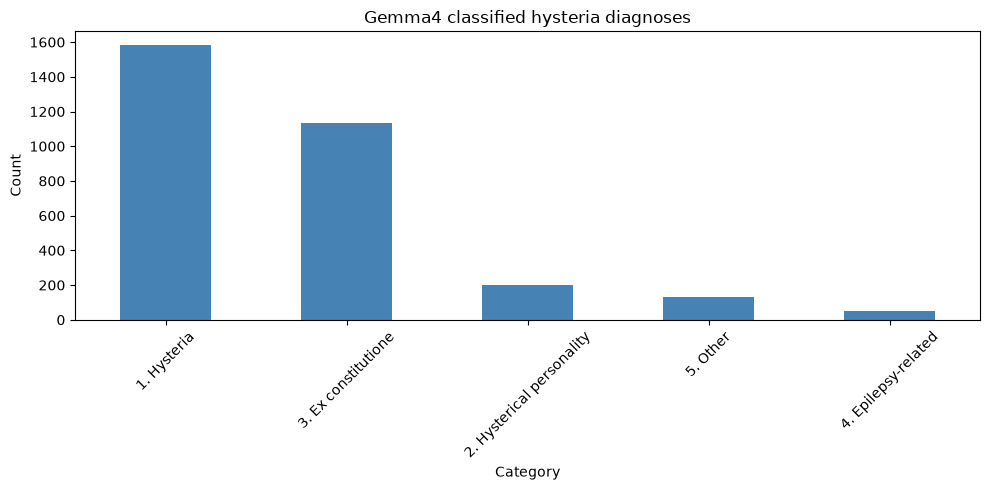

Plot lagret!


In [52]:
# Tell opp kategorier
kategori_telling = df_ferdig["kategori"].value_counts()

kategori_oversetting = {
    "1. Hysteria": "1. Hysteria",
    "2. Hysterisk personlighet": "2. Hysterical personality",
    "3. Ex constitutione": "3. Ex constitutione",
    "4. Epilepsi-relatert": "4. Epilepsy-related",
    "5. Annet": "5. Other"
}
kategori_telling.index = kategori_telling.index.map(kategori_oversetting)

fig, ax = plt.subplots(figsize=(10, 5))
kategori_telling.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Gemma4 classified hysteria diagnoses")
ax.set_xlabel("Category")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("../results/kategori_fordeling.png", dpi=150)
plt.show()

print("Plot lagret!")

In [53]:
from sklearn.metrics import classification_report
import pandas as pd

# Sørg for at kolonnene finnes
df_fasit["kategori_nr"] = df_fasit["kategori"].str[0]
df_fasit["fasit_str"] = df_fasit["fasit"].astype(str).str[0]


# Lag rapport som dictionary
rapport = classification_report(
    df_fasit["fasit_str"], 
    df_fasit["kategori_nr"],
    zero_division=0,
    output_dict=True
)

# Gjør om til pen tabell
df_rapport = pd.DataFrame(rapport).T
df_rapport = df_rapport.round(2)

# Bytt ut tallkoder med kategorinavn
kategorinavn = {
    "1": "Hysteria",
    "2": "Hysterical personality",
    "3": "Ex constitutione",
    "4": "Epilepsy-related",
    "5": "Other",
    "accuracy": "Accuracy",
    "macro avg": "Macro average",
}
df_rapport.index = df_rapport.index.map(lambda x: kategorinavn.get(x, x))

# Vis tabellen
df_rapport[["precision", "recall", "f1-score", "support"]].style\
    .background_gradient(subset=["precision", "recall", "f1-score"], cmap="Greens")\
    .format({"precision": "{:.2f}", "recall": "{:.2f}", 
             "f1-score": "{:.2f}", "support": "{:.0f}"})

,precision,recall,f1-score,support
Hysteria,0.95,0.86,0.90,22
Hysterical personality,0.95,0.63,0.76,30
Ex constitutione,1.00,1.00,1.00,20
Epilepsy-related,0.50,1.00,0.67,10
Other,0.85,0.94,0.89,18
Accuracy,0.85,0.85,0.85,1
Macro average,0.85,0.89,0.85,100
weighted avg,0.90,0.85,0.85,100
